<a href="https://colab.research.google.com/github/aashish7542/Practice-Codes/blob/main/Digit_recognition_investigation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

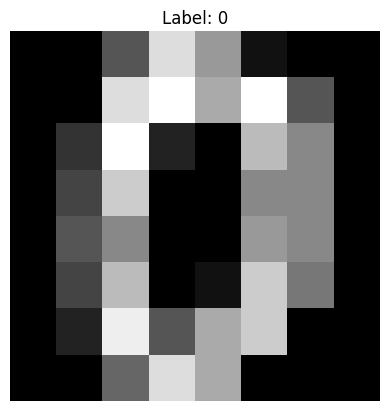

Pixel values:
 [[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]
Image shape: (8, 8)


In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

digits = load_digits()


image = digits.images[0]
label = digits.target[0]

plt.imshow(image, cmap="gray")
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()

print("Pixel values:\n", image)
print("Image shape:", image.shape)

In [3]:
# Flatten each image and scale pixel values from [0, 16] to [0, 1].
X = digits.images.reshape(len(digits.images), 64) / 16.0
y = digits.target

print("Feature matrix:", X.shape)
print("Labels:", y.shape)

Feature matrix: (1797, 64)
Labels: (1797,)


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.5, random_state=42, stratify=y_rest
)

print("Training:", len(y_train))
print("Validation:", len(y_val))
print("Test:", len(y_test))

Training: 1078
Validation: 359
Test: 360


In [5]:
from sklearn.neural_network import MLPClassifier

model = MLPClassifier(
    hidden_layer_sizes=(32,),
    activation="relu",
    solver="adam",
    batch_size=64,
    learning_rate_init=0.001,
    max_iter=200,
    random_state=42
)

model.fit(X_train, y_train)

print(f"Training accuracy:   {model.score(X_train, y_train):.1%}")
print(f"Validation accuracy: {model.score(X_val, y_val):.1%}")

Training accuracy:   100.0%
Validation accuracy: 97.5%


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Incorrect predictions: 9 out of 359


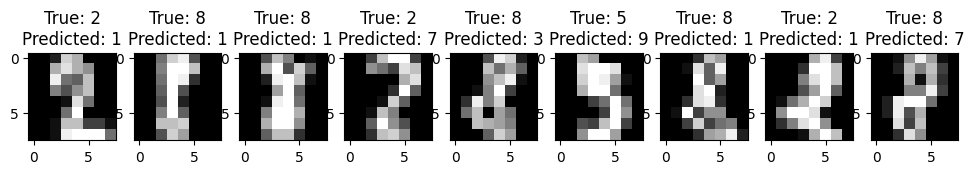

In [19]:
import numpy as np

val_predictions = model.predict(X_val)
mistakes = np.flatnonzero(val_predictions != y_val)

print(f"Incorrect predictions: {len(mistakes)} out of {len(y_val)}")

fig, axes = plt.subplots(1, 9, figsize=(12, 2))

for ax, i in zip(axes, mistakes[:9]):
    ax.imshow(X_val[i].reshape(8, 8), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"True: {y_val[i]}\nPredicted: {val_predictions[i]}")

for ax in axes:
    ax.axis()

plt.tight_layout
plt.show()

In [17]:
print(mistakes)
print(val_predictions[mistakes])
print(y_val[mistakes])


[  5  20  45  58  98 229 281 311 322]
[1 1 1 7 3 9 1 1 7]
[2 8 8 2 8 5 8 2 8]


So, there are some images that are ambiguous to even me. Now we can think if removing some patches will help the model see it clearly. First we will visualise how the images turn out to be when I remove a path at fixed cordinates in all of them.

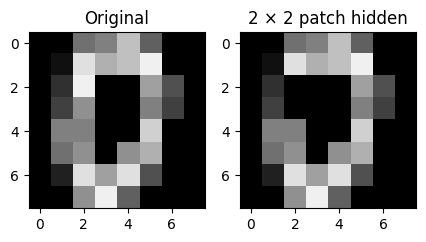

In [21]:
original = X_train[0].reshape(8, 8)
erased = original.copy()  # Preserve the original training image.

erased[2:4, 2:4] = 0

fig, axes = plt.subplots(1, 2, figsize=(5, 3))

for ax, img, title in zip(
    axes, [original, erased], ["Original", "2 × 2 patch hidden"]
):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis()

plt.show()

Now we will randomize the patch and also randomise their brightness. Note that we have already scaled the value of each pixen to the range of 0 to 1.

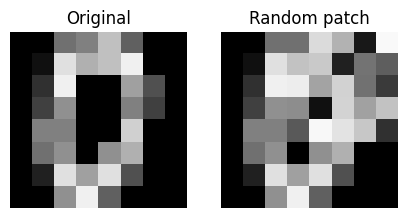

In [38]:
rng = np.random.default_rng(42)

def erase_patch(image, rng, size=5):
    erased = image.copy()
    height, width = image.shape

    row = rng.integers(0, height - size + 1)
    col = rng.integers(0, width - size + 1)

    erased[row:row + size, col:col + size] = rng.uniform(
        0, 1, size=(size, size)
    )
    return erased

erased = erase_patch(original, rng)

fig, axes = plt.subplots(1, 2, figsize=(5, 3))
for ax, img, title in zip(
    axes, [original, erased], ["Original", "Random patch"]
):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.show()

Now, let's see, without any further training, how our model responds to these patched images.

In [39]:
# Create a reproducible patched validation set.
val_rng = np.random.default_rng(123)

X_val_erased = np.array([
    erase_patch(row.reshape(8, 8), val_rng, size=2).ravel()
    for row in X_val
])

print(f"Clean validation:   {model.score(X_val, y_val):.1%}")
print(f"Patched validation: {model.score(X_val_erased, y_val):.1%}")

Clean validation:   97.5%
Patched validation: 93.0%


# A side detour

Before continuing to train our model on  new data with patches of size=2, I decided to explore how the model reacts to different patch sizes, ranging from 1 to 8. This is done using a for loop

--- Patch Size: 1 ---
Clean validation:   97.5%
Patched validation: 97.2%

--- Patch Size: 2 ---
Clean validation:   97.5%
Patched validation: 92.2%

--- Patch Size: 3 ---
Clean validation:   97.5%
Patched validation: 83.3%

--- Patch Size: 4 ---
Clean validation:   97.5%
Patched validation: 67.1%

--- Patch Size: 5 ---
Clean validation:   97.5%
Patched validation: 48.5%

--- Patch Size: 6 ---
Clean validation:   97.5%
Patched validation: 26.2%

--- Patch Size: 7 ---
Clean validation:   97.5%
Patched validation: 13.9%

--- Patch Size: 8 ---
Clean validation:   97.5%
Patched validation: 10.0%



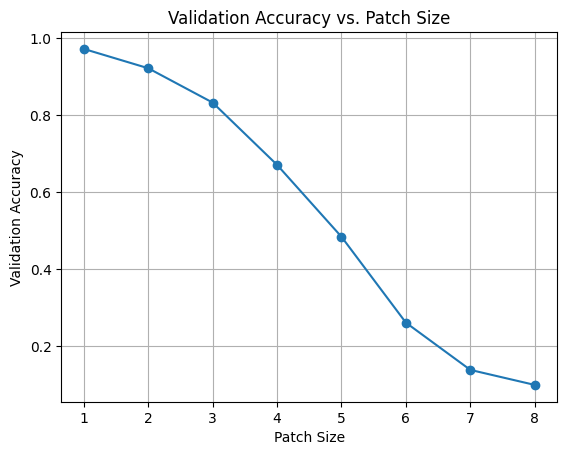

In [52]:
# Create a reproducible patched validation set
val_rng = np.random.default_rng(123)

# Define the patch sizes you want to test
sizes_to_test = np.arange(1,9)

val_accuracy = []

for size in sizes_to_test:
    # Generate the erased validation set for the current size
    X_val_erased_detour = np.array([
        erase_patch(row.reshape(8, 8), val_rng, size=size).ravel()
        for row in X_val
    ])

    # Calculate and print the results for this size
    clean_score = model.score(X_val, y_val)
    patched_score = model.score(X_val_erased_detour, y_val)

    print(f"--- Patch Size: {size} ---")
    print(f"Clean validation:   {clean_score:.1%}")
    print(f"Patched validation: {patched_score:.1%}\n")
    val_accuracy.append(patched_score)
plt.plot(sizes_to_test, val_accuracy, marker='o')
plt.xlabel('Patch Size')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy vs. Patch Size')
plt.grid(True)
plt.show()


# Let's continue the training

Now we will train two fresh networks with the same starting weights and training budget. One sees clean images; the other has a 50% chance of receiving a random patch on each image each epoch.

First, we will build the function that prepares one epoch’s training images:

In [41]:
def augment_training(X, rng, probability=0.5, size=2):
    augmented = X.copy()

    for i in range(len(X)):
        if rng.random() < probability:
            image = X[i].reshape(8, 8)
            augmented[i] = erase_patch(image, rng, size).ravel()

    return augmented

This preserves the original data and keeps the labels unchanged. Calling it again with the same ongoing random generator produces fresh patches.

We’ll use partial_fit: each call trains for one pass over the supplied data, retaining what the network has learned. This lets us refresh the patches between epochs. scikit-learn 1.9.1 documentation

In [47]:
from sklearn.base import clone

# Copy settings, but start with fresh, untrained models.
clean_model = clone(model)
erased_model = clone(model)

train_rng = np.random.default_rng(456)
classes = np.arange(10)

for epoch in range(200):
    X_augmented = augment_training(
        X_train, train_rng, probability=0.5, size=2
    )

    clean_model.partial_fit(X_train, y_train, classes=classes)
    erased_model.partial_fit(X_augmented, y_train, classes=classes)

for name, trained_model in [
    ("Clean training", clean_model),
    ("Erasing training", erased_model),
]:
    print(
        f"{name}: "
        f"clean accuracy = {trained_model.score(X_val, y_val):.1%}, "
        f"patched accuracy = {trained_model.score(X_val_erased, y_val):.1%}"
    )

Clean training: clean accuracy = 97.5%, patched accuracy = 92.8%
Erasing training: clean accuracy = 96.9%, patched accuracy = 93.9%


Changing the seeds changes the initial weights and the training patches. One run might get patches that preserve useful strokes; another might obscure more important clues.

We’ll keep the validation images fixed so the challenge stays the same.

We will repeat this experiment with random generated seeds. If the model helps in all of them, it means it is consistent.

In [48]:
results = []

for seed in range(5):
    clean_model = clone(model).set_params(random_state=seed)
    erased_model = clone(model).set_params(random_state=seed)
    train_rng = np.random.default_rng(1000 + seed)

    for epoch in range(200):
        X_augmented = augment_training(
            X_train, train_rng, probability=0.5, size=2
        )
        clean_model.partial_fit(X_train, y_train, classes=classes)
        erased_model.partial_fit(X_augmented, y_train, classes=classes)

    # Compare erasing training against clean training.
    clean_change = 100 * (
        erased_model.score(X_val, y_val)
        - clean_model.score(X_val, y_val)
    )
    patched_change = 100 * (
        erased_model.score(X_val_erased, y_val)
        - clean_model.score(X_val_erased, y_val)
    )

    results.append([clean_change, patched_change])

    print(
        f"Seed {seed}: clean change = {clean_change:+.2f} pp, " #pp means percentage points
        f"patched change = {patched_change:+.2f} pp"
    )

Seed 0: clean change = +0.28 pp, patched change = +1.95 pp
Seed 1: clean change = +0.00 pp, patched change = +0.56 pp
Seed 2: clean change = -0.56 pp, patched change = +0.84 pp
Seed 3: clean change = +0.84 pp, patched change = +2.79 pp
Seed 4: clean change = -0.56 pp, patched change = +0.84 pp


The patched improvement ranged from +0.56 to +2.79 percentage points—about 2–10 additional correct predictions per run.

Our earlier clean-accuracy drop wasn’t consistent. That’s why repeating experiments matters.

**Conclusion: For this network and data split, training with random 2 × 2 patches consistently improved accuracy on our fixed patched validation set, with approximately no average change on clean validation accuracy.**

#Back to detour
We have one remaining validation experiment. We originally predicted that small training patches would work better than very large ones, but we’ve only compared no erasing versus 2 × 2 patches.

Let’s compare training patch sizes 2 × 2, 4 × 4, and 6 × 6, keeping the erasing probability, five seeds, and training budget unchanged.

In [49]:
patch_results = {}

for size in [2, 4, 6]:
    scores = []

    for seed in range(5):
        candidate = clone(model).set_params(random_state=seed)
        train_rng = np.random.default_rng(1000 + seed)

        for epoch in range(200):
            X_augmented = augment_training(
                X_train, train_rng, probability=0.5, size=size
            )
            candidate.partial_fit(
                X_augmented, y_train, classes=classes
            )

        scores.append([
            candidate.score(X_val, y_val),
            candidate.score(X_val_erased, y_val)
        ])

    patch_results[size] = np.array(scores)
    averages = patch_results[size].mean(axis=0)

    print(
        f"Training patch {size}×{size}: "
        f"mean clean accuracy = {averages[0]:.1%}, "
        f"mean patched accuracy = {averages[1]:.1%}"
    )

Training patch 2×2: mean clean accuracy = 97.1%, mean patched accuracy = 94.2%
Training patch 4×4: mean clean accuracy = 96.6%, mean patched accuracy = 94.2%
Training patch 6×6: mean clean accuracy = 94.6%, mean patched accuracy = 91.9%


**Validation experiments complete.** We’ll now fix our choice at 2 × 2, with 50% erasing probability, and compare it against clean training on the untouched test set. We’ll use all five seeds rather than pick the best-performing run.

#Final Test Evaluation

In [51]:
# Create the test corruption once; keep it identical for every model.
test_rng = np.random.default_rng(789)

X_test_erased = np.array([
    erase_patch(row.reshape(8, 8), test_rng, size=2).ravel()
    for row in X_test
])

test_results = []

for seed in range(5):
    clean_model = clone(model).set_params(random_state=seed)
    erased_model = clone(model).set_params(random_state=seed)
    train_rng = np.random.default_rng(1000 + seed)

    for epoch in range(200):
        X_augmented = augment_training(
            X_train, train_rng, probability=0.5, size=2
        )
        clean_model.partial_fit(X_train, y_train, classes=classes)
        erased_model.partial_fit(X_augmented, y_train, classes=classes)

    test_results.append([
        clean_model.score(X_test, y_test),
        clean_model.score(X_test_erased, y_test),
        erased_model.score(X_test, y_test),
        erased_model.score(X_test_erased, y_test)
    ])

test_results = np.array(test_results)
means = test_results.mean(axis=0)

print(f"Clean training:   clean test = {means[0]:.1%}, "
      f"patched test = {means[1]:.1%}")
print(f"Erasing training: clean test = {means[2]:.1%}, "
      f"patched test = {means[3]:.1%}")

patched_gains = 100 * (test_results[:, 3] - test_results[:, 1])
print("Patched gains per seed (percentage points):",
      np.round(patched_gains, 2))

Clean training:   clean test = 96.8%, patched test = 90.7%
Erasing training: clean test = 96.6%, patched test = 92.9%
Patched gains per seed (percentage points): [3.33 2.78 1.67 1.11 2.5 ]


Our conclusion is:
In this experiment, random 2 × 2 erasing during training consistently improved patched test accuracy by about 2.2 percentage points across five seeds, with a 0.2-point average decrease on clean images.

Tradeoff: slightly lower average clean accuracy.
Limitation: robustness evaluated only on one specific corruption. Because we only investigated 2x2 patches. Blur and brightness changes remain untested.